# Teks — Klasifikasi dengan Fine-tune Transformer (IndoBERT)
**Kapan dipakai:** butuh skor tertinggi dan ada GPU. Seluruh bobot model pretrained ikut
dilatih ulang pada data soal.

**Langkah:** tokenisasi → loop latih PyTorch biasa (AdamW + warmup) → F1 macro → submission.
`EPOCHS` dibuat kecil agar cepat; naikkan saat lomba bila waktu cukup.

**Data demo:** SmSA (sentimen Bahasa Indonesia).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
from sklearn.model_selection import train_test_split
from transformers import AutoModelForSequenceClassification, AutoTokenizer
from transformers import get_linear_schedule_with_warmup

## Konfigurasi
`LABELS`: urutan label → nomor kelas 0, 1, 2 di dalam model.

In [2]:
DATA_FOLDER = "../../data_latihan/text/sentiment"   # GANTI saat lomba
TRAIN_CSV = f"{DATA_FOLDER}/smsa_train.csv"
TEST_CSV = f"{DATA_FOLDER}/smsa_test.csv"

PRETRAINED = "../../pretrained/indobert"
# PRETRAINED = "../../pretrained/distilbert_id"   # lebih ringan
# PRETRAINED = "../../pretrained/minilm"          # multibahasa, kecil
# PRETRAINED = "../../pretrained/distilbert_en"   # teks bahasa Inggris

TEXT_COL = "text"
TARGET = "label"
LABELS = ["negative", "neutral", "positive"]
EPOCHS = 2
MAX_LENGTH = 64          # token maksimal per teks
BATCH_SIZE = 16
LEARNING_RATE = 3e-5
SEED = 42
DEVICE = "cpu"
if torch.cuda.is_available():
    DEVICE = "cuda"
torch.manual_seed(SEED)

## Baca data

In [3]:
train = pd.read_csv(TRAIN_CSV)
test = pd.read_csv(TEST_CSV)
train[TEXT_COL] = train[TEXT_COL].fillna("")
test[TEXT_COL] = test[TEXT_COL].fillna("")
print("train:", train.shape, "| test:", test.shape)
train.head()

train: (5148, 3) | test: (1260, 2)


,id,text,label
0,1,kenapa lumayan enak ? karena ada sushi lain ya...,negative
1,2,berarti staff nya anies yang tidak becus mengu...,negative
2,3,orang cina makanan legendaris sudah lama bange...,negative
3,4,"mental apa ini pak jokowi , bagaimana ini pak ...",negative
4,5,selama iblis binatang ini jadi kapolri jangan ...,negative


## EDA: jumlah per kelas dan panjang teks

label
negative    2000
positive    2000
neutral     1148
Name: count, dtype: int64


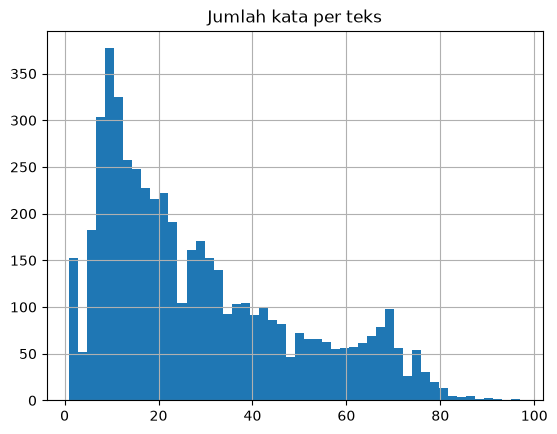

In [4]:
print(train[TARGET].value_counts())
word_counts = train[TEXT_COL].str.split().str.len()
word_counts.hist(bins=50)
plt.title("Jumlah kata per teks")
plt.show()

## Split train / validasi
Label teks diubah ke nomor: "negative" → 0, "neutral" → 1, "positive" → 2.

In [5]:
y_all = train[TARGET].map(LABELS.index).to_numpy()
X_train, X_val, y_train, y_val = train_test_split(
    list(train[TEXT_COL]), y_all, test_size=0.2, stratify=y_all, random_state=SEED
)

## Model: transformer pretrained + kepala klasifikasi baru

In [6]:
tokenizer = AutoTokenizer.from_pretrained(PRETRAINED, local_files_only=True)
model = AutoModelForSequenceClassification.from_pretrained(
    PRETRAINED, num_labels=len(LABELS), ignore_mismatched_sizes=True, local_files_only=True
)
model = model.to(DEVICE)

[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `5`.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: ../../pretrained/indobert
Key               | Status  | 
------------------+---------+-
classifier.bias   | MISSING | 
classifier.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


## Latih (loop PyTorch biasa)
Tiap epoch: acak urutan → potong per batch → hitung loss → mundur (backward) → perbarui bobot.

In [7]:
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=0.01)
total_steps = EPOCHS * (len(X_train) // BATCH_SIZE + 1)
scheduler = get_linear_schedule_with_warmup(optimizer, int(0.1 * total_steps), total_steps)
random_generator = np.random.default_rng(SEED)

for epoch in range(EPOCHS):
    model.train()
    order = random_generator.permutation(len(X_train))
    for start in range(0, len(order), BATCH_SIZE):
        batch_rows = order[start:start + BATCH_SIZE]
        batch_texts = []
        for row in batch_rows:
            batch_texts.append(X_train[row])
        batch = tokenizer(batch_texts, truncation=True, max_length=MAX_LENGTH, padding=True,
                          return_tensors="pt").to(DEVICE)
        batch_labels = torch.tensor(y_train[batch_rows]).to(DEVICE)
        loss = model(**batch, labels=batch_labels).loss
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        scheduler.step()
        optimizer.zero_grad()
    print("epoch", epoch + 1, "loss terakhir:", round(loss.item(), 4))

epoch 1 loss terakhir: 0.0263


epoch 2 loss terakhir: 0.0265


## Evaluasi di validasi
`predict_classes`: tebak nomor kelas untuk daftar teks, 64 teks sekaligus.

F1 macro: 0.9242
              precision    recall  f1-score   support

    negative       0.92      0.92      0.92       400
     neutral       0.93      0.90      0.92       230
    positive       0.92      0.94      0.93       400

    accuracy                           0.93      1030
   macro avg       0.93      0.92      0.92      1030
weighted avg       0.93      0.93      0.93      1030



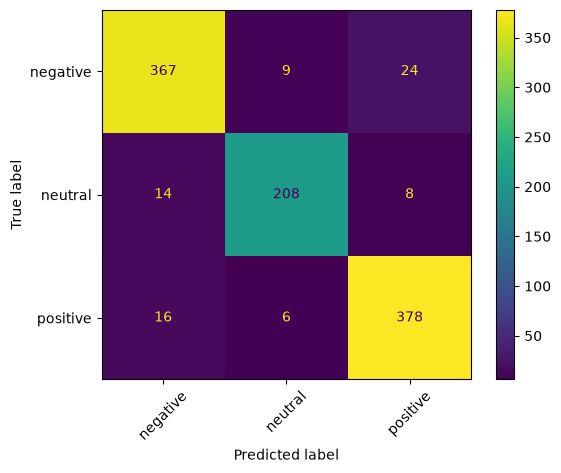

In [8]:
def predict_classes(texts):
    model.eval()
    classes = []
    with torch.no_grad():
        for start in range(0, len(texts), 64):
            batch = tokenizer(texts[start:start + 64], truncation=True, max_length=MAX_LENGTH,
                              padding=True, return_tensors="pt").to(DEVICE)
            logits = model(**batch).logits
            classes.extend(logits.argmax(-1).tolist())
    return np.array(classes)


val_predictions = predict_classes(X_val)
print("F1 macro:", round(f1_score(y_val, val_predictions, average="macro"), 4))
print(classification_report(y_val, val_predictions, target_names=LABELS))
ConfusionMatrixDisplay.from_predictions(y_val, val_predictions, display_labels=LABELS,
                                        xticks_rotation=45)
plt.show()

## Submission
Fine-tune tidak dilatih ulang di seluruh data (menghemat waktu GPU). Model di atas
(dilatih 80% train) dipakai untuk memprediksi test. Nomor kelas diubah kembali ke label teks.

In [9]:
predictions = predict_classes(list(test[TEXT_COL]))

submission = pd.DataFrame()
submission["id"] = test["id"]
submission["label"] = np.array(LABELS)[predictions]
submission.to_csv("submission.csv", index=False)
submission.head()

,id,label
0,100001,neutral
1,100002,negative
2,100003,positive
3,100004,positive
4,100005,negative
